# 00 · Data loading and quality checks

**Question.** Can the 68 Parquet files be used as they are, and what must the analysis handle?
**Answer.** Yes, with four caveats handled downstream: one truncated file, a data gap on 2025-03-27, 10.4% of events without session id, and partial first and last days.
**Method.** DuckDB reads the Parquet files in place through the `events` view (`game_events.data`). The checks are the ones run before every export by `python -m game_events checks`.

In [1]:
import matplotlib.pyplot as plt

from game_events.checks import run_checks
from game_events.data import connect_events
from game_events.queries import build_base_tables

con, readable, unreadable = connect_events()
build_base_tables(con)
print(f"{len(readable)} readable files, {len(unreadable)} skipped")

67 readable files, 1 skipped


## 1. Automated checks

In [2]:
run_checks(con, readable, unreadable)

,check,result,status,detail
0,readable Parquet files,67 of 68,warning,part-00049-a228a717-fd60-4fea-83bd-edbe775a63d...
1,events without player id,0,ok,
2,events without timestamp,0,ok,
3,events without session id,10.4%,ok,"server-side events, excluded from session metrics"
4,duplicate event ids on 2025-03-15,0,ok,
5,days with less than half the median active pla...,2025-03-27,ok,expected: 2025-03-27 (config.GAP_DAY)
6,ad impressions with a usable revenue,100.0%,ok,"revenue under `value` before 2025-03-29, `amou..."


## 2. Schema

`event_properties` and `user_properties_custom` are text maps; the timestamp is stored as text and cast in the view.

In [3]:
con.sql("DESCRIBE events").show(max_width=200)
con.sql("SELECT * FROM events LIMIT 3").show(max_width=250)

┌────────────────────────┬───────────────────────┬─────────┬─────────┬─────────┬─────────┐
│      column_name       │      column_type      │  null   │   key   │ default │  extra  │
│        varchar         │        varchar        │ varchar │ varchar │ varchar │ varchar │
├────────────────────────┼───────────────────────┼─────────┼─────────┼─────────┼─────────┤
│ event_id               │ VARCHAR               │ YES     │ NULL    │ NULL    │ NULL    │
│ event_name             │ VARCHAR               │ YES     │ NULL    │ NULL    │ NULL    │
│ event_properties       │ MAP(VARCHAR, VARCHAR) │ YES     │ NULL    │ NULL    │ NULL    │
│ event_receive_time     │ VARCHAR               │ YES     │ NULL    │ NULL    │ NULL    │
│ user_id                │ VARCHAR               │ YES     │ NULL    │ NULL    │ NULL    │
│ user_session_id        │ VARCHAR               │ YES     │ NULL    │ NULL    │ NULL    │
│ user_session_issued_at │ VARCHAR               │ YES     │ NULL    │ NULL    │ NULL    │

## 3. Size of the dataset

In [4]:
con.sql("""
    SELECT COUNT(*)                                                         AS events,
           COUNT(DISTINCT user_id)                                          AS players,
           COUNT(DISTINCT user_session_id) FILTER (WHERE user_session_id <> '') AS sessions,
           MIN(ts)                                                          AS first_event,
           MAX(ts)                                                          AS last_event
    FROM events
""").show(max_width=200)

┌──────────┬─────────┬──────────┬─────────────────────┬─────────────────────┐
│  events  │ players │ sessions │     first_event     │     last_event      │
│  int64   │  int64  │  int64   │      timestamp      │      timestamp      │
├──────────┼─────────┼──────────┼─────────────────────┼─────────────────────┤
│ 70931231 │   71679 │   275697 │ 2025-02-28 05:58:43 │ 2025-04-10 20:37:24 │
└──────────┴─────────┴──────────┴─────────────────────┴─────────────────────┘



## 4. Daily active players

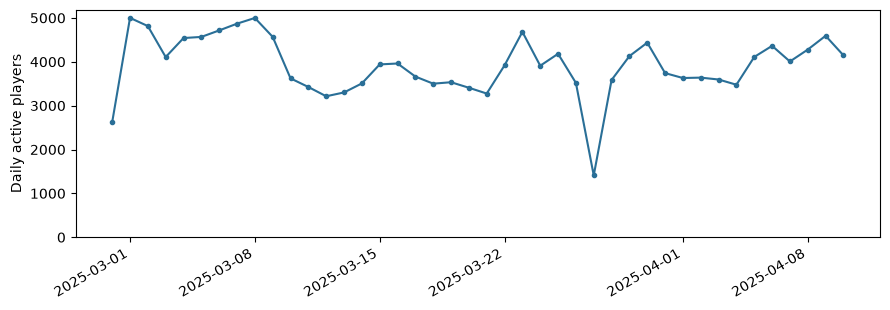

In [5]:
dau = con.execute("SELECT day, COUNT(*) AS players FROM active_days GROUP BY 1 ORDER BY 1").df()
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(dau["day"], dau["players"], color="#2a6f97", marker=".")
ax.set_ylabel("Daily active players")
ax.set_ylim(0, None)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

## Findings

- **Files.** 67 of the 68 Parquet files are readable. `part-00049` is truncated (no footer) and is skipped in every notebook (see `data/README.md`).
- **Size.** 70,931,231 events, 71,679 players and 275,697 sessions (events with an empty session id are not counted), from 2025-02-28 05:58 to 2025-04-10 20:37. The first and last days are partial.
- **Duplicates.** No duplicated `event_id` on 2025-03-15 (1,489,753 events, all distinct). The check covers one day only, for memory reasons.
- **Missing values.** No NULL player, session id or timestamp, but this does not mean the columns are filled: `user_session_id` is an empty string on 10.4% of events (notebook 01). 31,977 events have no platform.
- **Daily active players.** Between about 3,200 and 5,000 per day, except 2025-03-27 (1,410). This drop is a data gap of unknown cause, handled in notebooks 02 and 03.